In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
import numpy as np

In [2]:
def nucleotide_to_codons(seq):
    """
    Convert a nucleotide sequence into codons.

    Parameters:
    seq   : str, nucleotide sequence (A,T,G,C)
    frame : int, reading frame (1, 2, or 3)

    Returns:
    list of codons (strings of length 3)
    """
    codons = []

    for i in range(0, len(seq) - 2, 3):
        codons.append(seq[i:i+3])

    return codons
genetic_code = {
    "TTT":"F","TTC":"F","TTA":"L","TTG":"L",
    "CTT":"L","CTC":"L","CTA":"L","CTG":"L",
    "ATT":"I","ATC":"I","ATA":"I","ATG":"M",
    "GTT":"V","GTC":"V","GTA":"V","GTG":"V",

    "TCT":"S","TCC":"S","TCA":"S","TCG":"S",
    "CCT":"P","CCC":"P","CCA":"P","CCG":"P",
    "ACT":"T","ACC":"T","ACA":"T","ACG":"T",
    "GCT":"A","GCC":"A","GCA":"A","GCG":"A",

    "TAT":"Y","TAC":"Y","TAA":"*","TAG":"*",
    "CAT":"H","CAC":"H","CAA":"Q","CAG":"Q",
    "AAT":"N","AAC":"N","AAA":"K","AAG":"K",
    "GAT":"D","GAC":"D","GAA":"E","GAG":"E",

    "TGT":"C","TGC":"C","TGA":"*","TGG":"W",
    "CGT":"R","CGC":"R","CGA":"R","CGG":"R",
    "AGT":"S","AGC":"S","AGA":"R","AGG":"R",
    "GGT":"G","GGC":"G","GGA":"G","GGG":"G"
}

def nucleotide_to_protein(seq):
    """
    Translate a nucleotide sequence into a protein.

    Parameters:
    seq          : str, nucleotide sequence

    Returns:
    protein sequence (string)
    """
    protein = ""

    for i in range( 0,len(seq) - 2, 3):
        codon = seq[i:i+3]
        aa = genetic_code.get(codon, "X")  # X = unknown/invalid codon

        protein += aa
    
    return protein

# Treat Roux data

In [3]:
data_seq=[]
ID=[]
for seq_record in SeqIO.parse("All_DGR_targets.faa", "fasta"):
    seq=str(seq_record.seq)
    data_seq.append(seq)
    ID.append(seq_record.id)
dict_target=pd.DataFrame({'id': ID, 'target': data_seq})

TRseq=[]
TRid=[]
VRseq=[]
VRid=[]
for seq_record in SeqIO.parse("All_DGR_TR_VR.fna", "fasta"):
    seq=str(seq_record.seq)
    st=seq_record.id
    if st[-2:]=='TR':
        TRid.append(st[:-3].split('|')[1])
        TRseq.append(seq)
    else:
        VRid.append(st[:-3].split('|')[1])
        VRseq.append(seq)

dict_TR = pd.DataFrame({'id': TRid, 'TR seq': TRseq})

dict_VR = pd.DataFrame({'id': VRid, 'VR seq': VRseq})

df = pd.merge(dict_TR, dict_VR, on="id") 
df=pd.merge(df,dict_target,on="id")

NameError: name 'SeqIO' is not defined

# Histogram

In [4]:
df=pd.read_csv('data_Roux.csv')
df
TR=df['TR seq']
VR=df['VR seq']
Frame=df['reading frame']

In [42]:
def compute_L_first_last_A(TR, VR):
    n = len(TR)

    # 1. positions des A mutés
    A_mut = [i for i in range(n) if VR[i] != TR[i] and TR[i]=='A']

    if len(A_mut) < 2:
        return None  # pas d'intervalle exploitable

    first_A = A_mut[0]
    last_A = A_mut[-1]

    # 2. découpage en codons
    L = 0
    for i in range(first_A,last_A+1):
        if TR[i]=='A':
            L+=1
    return L

def compute_len_first_last_A(TR, VR):
    n = len(TR)

    # 1. positions des A mutés
    A_mut = [i for i in range(n) if VR[i] != TR[i] and TR[i]=='A']

    if len(A_mut) < 2:
        return None  # pas d'intervalle exploitable

    first_A = A_mut[0]
    last_A = A_mut[-1]

    return last_A-first_A+1


In [43]:
Llist=[]
len_list=[]
for k in range(len(TR)):
    if len(TR[k])==len(VR[k]):
        Llist.append(compute_L_first_last_A(TR[k].upper(), VR[k].upper()))
        len_list.append(compute_len_first_last_A(TR[k].upper(), VR[k].upper()))

In [44]:


# GLOBAL STYLE SETTINGS (run once)

plt.rcParams.update({

    # --- FONT SIZES ---
    "font.size": 24,              # base font size
    "axes.titlesize": 20,         # title
    "axes.labelsize": 36,         # x/y labels
    "xtick.labelsize": 36,
    "ytick.labelsize": 36,
    "legend.fontsize": 16,

    # --- LINES ---
    "lines.linewidth": 5,
    "lines.markersize": 16,

    # --- FIGURE / AXIS ---
    "figure.figsize": (8, 6),
    "figure.dpi": 120,
    "axes.linewidth": 1.5,        # thicker axis spines

    # --- TICKS ---
    "xtick.major.size": 15,
    "xtick.major.width": 3,
    "ytick.major.size": 15,
    "ytick.major.width": 3,

    # --- LEGEND ---
    "legend.frameon": True,
    "legend.framealpha": 0.8,
    "legend.fancybox": True,

    # --- GRID (optional) ---
    #"axes.grid": True,
    #"grid.alpha": 0.3,
})


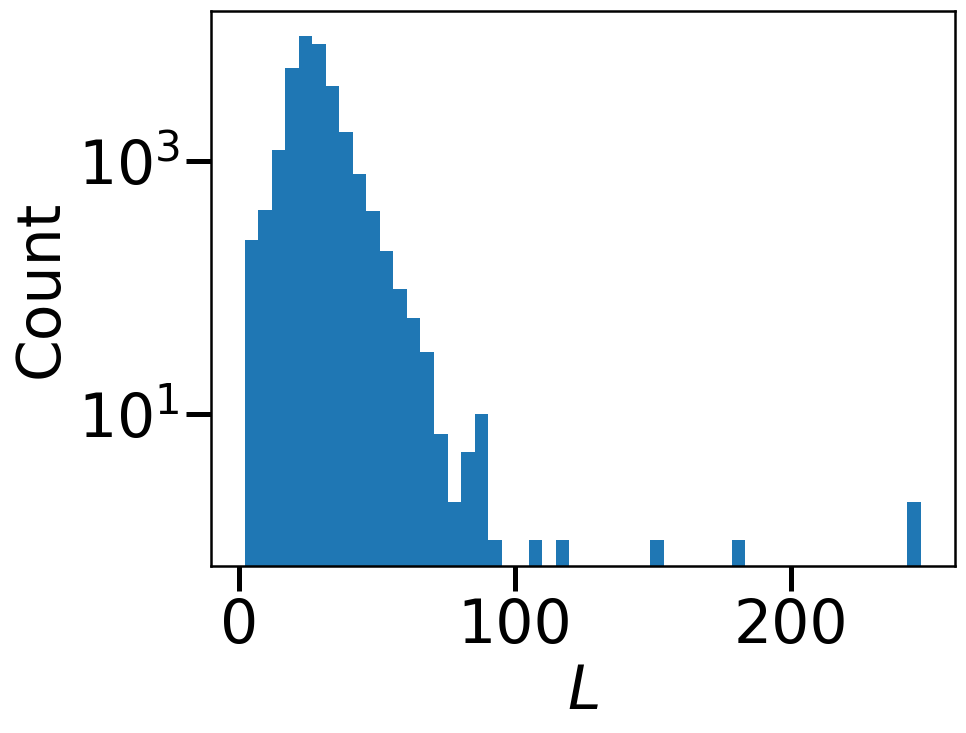

In [45]:
Llist=np.array(Llist)
Llist=Llist[Llist!=None]
plt.hist(Llist,bins=50)
plt.xlabel(r'$L$')
plt.ylabel('Count')
plt.semilogy()
plt.savefig('Count_L.svg')
plt.savefig('Count_L.png')

In [46]:
import numpy as np
np.mean(Llist),np.std(Llist)

(26.978694911127345, 8.350012076710465)

In [52]:
np.percentile(Llist,2.5),np.percentile(Llist,97.5)

(13.0, 46.0)

In [54]:
np.percentile(Llist,95)

41.0

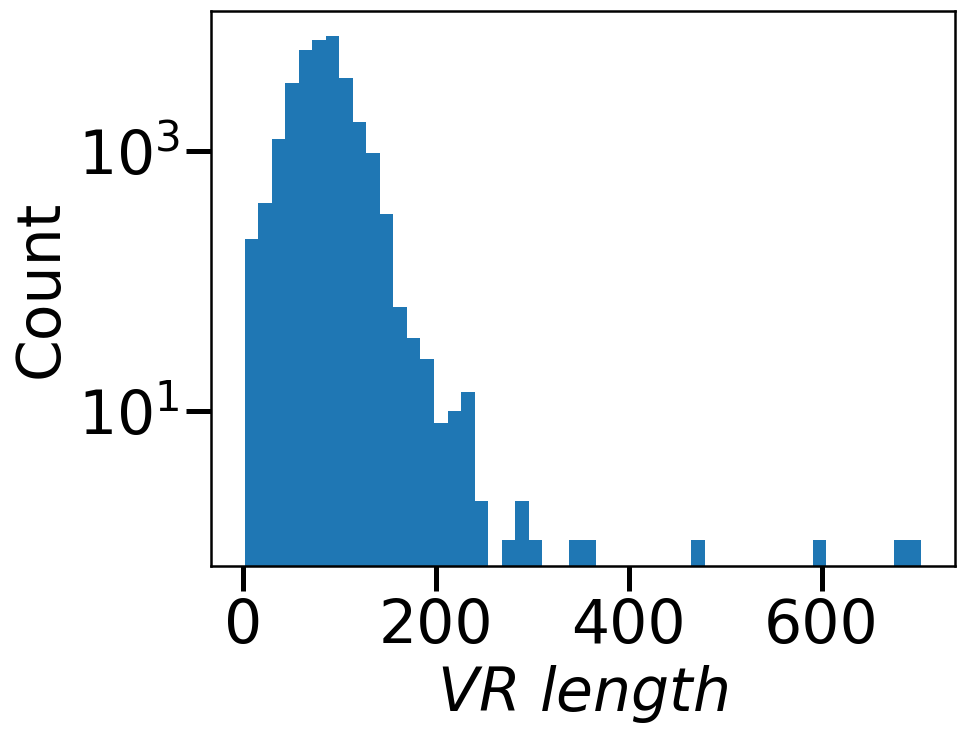

In [48]:
len_list=np.array(len_list)
len_list=len_list[len_list!=None]
plt.hist(len_list,bins=50)
plt.xlabel(r'$VR~length$')
plt.ylabel('Count')
plt.semilogy()
plt.savefig('Count_len.svg')
plt.savefig('Count_len.png')

In [49]:
np.mean(len_list),np.std(len_list)

(82.69971999026053, 26.378562664019636)

In [51]:
np.percentile(len_list,2.5),np.percentile(len_list,97.5)

(34.0, 139.0)

In [53]:
np.percentile(len_list,95)

126.0